# Partie I : Exploration, preprocessing, non supervisé

**Objectif de ce notebook** : charger le dataset *Myocardial infarction complications* et produire trois objets, utilisés ensuite par tout le groupe :

| Objet | Contenu |
|---|---|
| `y` | la cible : le patient est-il décédé (1) ou a-t-il survécu (0) ? |
| `X_admission` | les variables connues **à l'admission** à l'hôpital |
| `X_jour3` | les variables connues **au 3ᵉ jour** (toutes les variables d'entrée) |

**Pourquoi deux jeux de variables ?** On veut savoir si l'on peut prédire les complications dès l'arrivée du patient, puis si les informations recueillies pendant 3 jours améliorent la prédiction. Utiliser au jour 0 une information qui n'existe qu'au jour 3 serait de la **fuite de données** (*data leakage*) : le modèle paraîtrait excellent mais serait inutilisable en pratique.

Le dataset contient 1700 patients, 111 variables d'entrée (*features*) et 12 complications possibles.

## 1. Import des bibliothèques

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

## 2. Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. La cellule ci-dessous cherche à plusieurs endroits et affiche un message clair si elle ne trouve rien (c'était la cause du `FileNotFoundError`).

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle.

In [3]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : data/Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


Les valeurs manquantes sont des **cases vides** dans le CSV, que pandas lit directement comme `NaN` (pas besoin de `na_values="?"`).

## 3. Séparer les variables d'entrée et les complications

Les 12 dernières colonnes sont des **complications** (ce qu'on veut prédire). Toutes les autres sont des variables d'entrée.

On les sélectionne **par leur nom** et non par leur position (`iloc[:, 2:113]`). Avec un numéro, un décalage d'une colonne passe inaperçu et peut mettre une complication dans `X`, ce qui donne une fuite de données.

In [23]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

X_all = df.drop(columns=COMPLICATIONS)


## 4. La cible `y` : décès ou survie

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On la **binarise** : 0 = survie, 1 = décès (quelle qu'en soit la cause). On obtient un problème de classification binaire.

Répartition de la variable LET_IS
LET_IS
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%


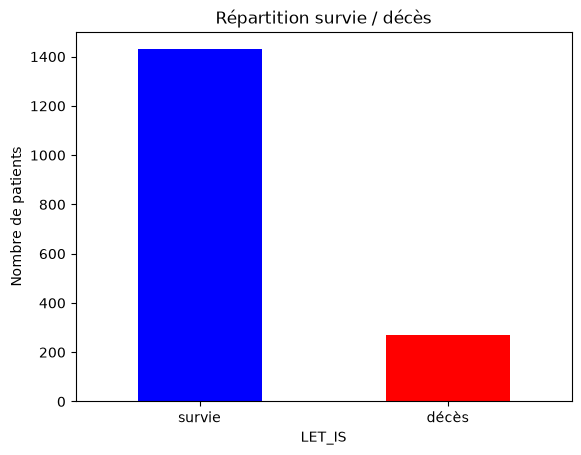

In [20]:
y = df["LET_IS"]

# On binarise la variable letale : 0 = survie, 1 = décès

for i in range(len(y)): 
    if y.iloc[i] > 0: 
        y.iloc[i] = 1

print("Répartition de la variable LET_IS")
print(y.value_counts().rename({0: "survie", 1: "décès"}))
print("Proportion de décès :", f"{y.mean():.1%}")

y.value_counts().rename({0: "survie", 1: "décès"}).plot(kind="bar", color=["blue", "red"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

**À retenir** : les classes sont **déséquilibrées** (les décès sont une minorité). L'*accuracy* ne suffira donc pas : un modèle qui prédit toujours « survie » aurait un score élevé tout en étant inutile. On utilisera le recall.

L'objectif de notre modèle est de rater le moins de decès possible, nous allons donc porter une attention particulière au recall.

## 5. Quelles variables sont disponibles à quel moment ?

Les colonnes suivent l'ordre chronologique du dossier médical. Certaines ne sont connues que **plus tard** dans l'hospitalisation :

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements des urgences | `NA_KB`, `NOT_NA_KB`, `LID_KB`, `NITR_S` | à l'admission (équipe d'urgence) |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | idem |
| Anti-inflammatoires en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | idem |
| Autres traitements en soins intensifs | `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour (moment exact à vérifier) |


In [33]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».
COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True  # à décider en groupe

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

## 6. Construction de `X_admission` et `X_jour3`

- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour).
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

On garde des **DataFrames** (avec les noms de colonnes) et on ne les convertit pas en tableaux numpy : sans les noms, on ne peut plus interpréter les résultats (importance des variables, SHAP, arbre de décision).

In [34]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 95)
Colonnes retirées pour l'admission : 16


## 7. Exploration des données de `X_admission` et `X_jour3`

On cherche a donnée un type chacune des variables qui vont nous servir à entrainer le modèle. On distingue 3 types de variables : 
- `binaire` pour les variables binaire
- `ordinal` (on place le seuil ordinale à 10)
- `continue`

On affiche également le pourcentage manquant pour chaque colonne

In [51]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())

for t in ["binaire", "ordinale", "continue"]:
    print(f"\n=== Variables {t}s ===")
    display(resume_all[resume_all["type"] == t].drop(columns="type").head())
    

type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64

=== Variables binaires ===


,nb_modalites,min,max,moyenne,% manquants
SEX,2,0.0,1.0,0.626471,0.000000
IBS_NASL,2,0.0,1.0,0.375000,95.764706
SIM_GIPERT,2,0.0,1.0,0.033688,0.470588
nr_11,2,0.0,1.0,0.025015,1.235294
nr_01,2,0.0,1.0,0.002382,1.235294



=== Variables ordinales ===


,nb_modalites,min,max,moyenne,% manquants
INF_ANAM,4,0.0,3.0,0.554835,0.235294
STENOK_AN,7,0.0,6.0,2.316186,6.235294
FK_STENOK,5,0.0,4.0,1.205286,4.294118
IBS_POST,3,0.0,2.0,1.160703,3.000000
GB,4,0.0,3.0,1.393258,0.529412



=== Variables continues ===


,nb_modalites,min,max,moyenne,% manquants
AGE,62,26.0,92.0,61.856974,0.470588
S_AD_KBRIG,30,0.0,260.0,136.907051,63.294118
D_AD_KBRIG,21,0.0,190.0,81.394231,63.294118
S_AD_ORIT,32,0.0,260.0,134.588276,15.705882
D_AD_ORIT,20,0.0,190.0,82.749477,15.705882


On affiche ici le pourcentage de valeur manquant par patient (par ligne)

In [52]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)

resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)

display(resume_patient.head())

,% manquants
ID,
1,8.11
2,2.70
3,2.70
4,8.11
5,2.70


Étude des données decès / survivant

In [53]:
n_surv, n_deces = (y == 0).sum(), (y == 1).sum()
print(f"Survie : {n_surv} ({n_surv/len(y):.1%}) | Décès : {n_deces} ({n_deces/len(y):.1%})")
print(f"Ratio : 1 décès pour {n_surv/n_deces:.1f} survivants")

Survie : 1429 (84.1%) | Décès : 271 (15.9%)
Ratio : 1 décès pour 5.3 survivants


Cause de décès (sur la database avant la bianarisation de le colonnes "LET_IS")

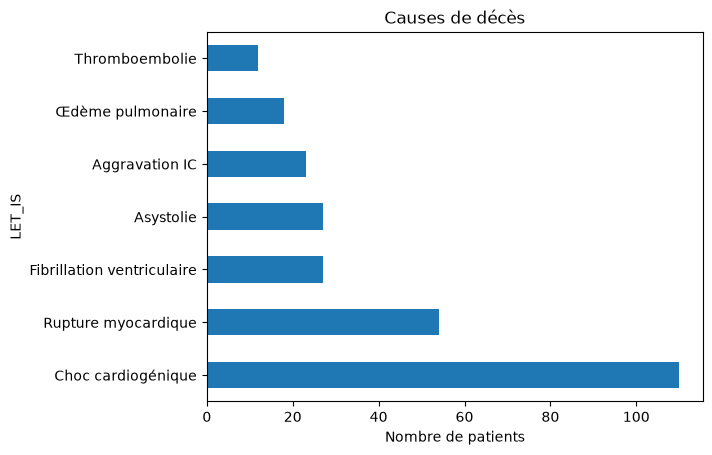

In [54]:
causes = {1: "Choc cardiogénique", 2: "Œdème pulmonaire", 3: "Rupture myocardique",
          4: "Aggravation IC", 5: "Thromboembolie", 6: "Asystolie", 7: "Fibrillation ventriculaire"}
df.loc[df["LET_IS"] > 0, "LET_IS"].map(causes).value_counts().plot(kind="barh")
plt.xlabel("Nombre de patients"); plt.title("Causes de décès"); plt.show()